# Chapter 6. Memory Capacity

In this chapter, we introduce a measure to evaluate past inputs held in the reservoir.
We implement two measures: memory function and memory capacity, and learn how to use them.

## Introduction

The memory function and memory capacity are metrics proposed by H. Jaeger<sup>[1]</sup> to quantify how well a dynamical system can retain past inputs.
Consider an $N$-dimensional dynamical system with input $x[k]$ and an output $\hat{y}[k]$ defined by a linear mapping $g: \mathbb{R}^N \to \mathbb{R}$, expressed as follows:

$$
\renewcommand{\Tau}{\mathrm{T}}
\renewcommand{\Zeta}{\mathrm{Z}}
\begin{align*}
x[k+1] &= f \left(x[k],\zeta[k+1]\right) \\
\hat{y}[k] &= g (x[k])
.\end{align*}
$$

Since $g$ is linear, the output $\hat{y}[k]$ can be expressed using a coupling parameter $W^\mathrm{out} \in \mathbb{R}^{1\times(N+1)}$ as follows:

$$
\begin{align*}
\hat{y}[k] &= \hat{w} [1 ; x[k]] \\
&= \hat{w} {[1 \quad x_1[k] \quad \cdots \quad x_{N}[k]]}^\top \\
&= \hat{w}_0 + \sum_{i=1}^{N} \hat{w}_i x_{i}[k]
.\end{align*}
$$

Assume that both the input $\zeta[k]$ and the internal state $x[k]$ are stationary, i.e., their mean and variance are constant over time.
The memory function $\mathrm{MF}[\tau]$ evaluates how well the input $\zeta^\tau[k]:=\zeta[k-\tau]$ from $\tau~(\geq 0)$ steps ago can be reconstructed from the internal state $x[k]$.
It is defined as

$$
\begin{align*}
\mathrm{MF}[\tau] :=& \max_{\hat{w}} \rho^2[\zeta^\tau, \hat{y}] \\
=& \max_{\hat{w}} \frac{\mathrm{Cov}^2[\zeta^\tau, \hat{y}]}{\mathrm{Var}[\zeta^\tau]\mathrm{Var}[\hat{y}]}
,\end{align*}
$$

where $\rho$ represents the correlation coefficient, $\mathrm{Cov}$ denotes covariance, and $\mathrm{Var}$ represents variance.
Since the absolute value of the correlation coefficient is at most $1$, the following inequality holds:

$$
\begin{align*}
0 \leq \mathrm{MF}[\tau] \leq 1
.\end{align*}
$$

Finally, the memory capacity $\mathrm{MC}$ is defined as the sum of the memory functions over all past inputs, as expressed in the following equation:

$$
\begin{align*}
\mathrm{MC} := \sum_{\tau=0}^{\infty} \mathrm{MF}[\tau]
.\end{align*}
$$

In particular, when the input is i.i.d., meaning the values of $\zeta[k]$ are sampled independently at each time step, the following inequality is known to hold

$$
\begin{align*}
\mathrm{MC} \leq r \leq N
,\end{align*}
$$

where $r$ represents the rank of $x[k]$, indicating that the memory capacity is limited by the number of linearly independent components at most (derivation is provided in the advanced exercises).

## Exercises and demonstrations

Let's move on to the exercise and demonstration.
In addition to the basic libraries used in the previous chapter, you can also use the `ESN` and `Linear` classes/functions that we implemented previously via `import`.
Please execute the following cell.

By the way, you can check the internal implementations of `ESN` and `Linear`either by uncommenting the lines after `import inspect` or by using `...?? / ??...`.

In [2]:
import sys

import numpy as np
import scipy as sp

if "google.colab" in sys.modules:
    from google.colab import drive  # type: ignore

    # NOTE: Set `save_to_drive` to True to save your progress to Google Drive.
    # After running this cell, you may need to reopen this notebook directly from Google Drive (https://drive.google.com).
    # Then, set both `save_to_drive` and `project_path` to your preferred values and run this cell again.
    save_to_drive = False  # @param {type:"boolean"}

    # NOTE: Specify the destination path for project extraction (Default: Google Drive root directory).
    project_path = ""  # @param {type:"string"}

    if save_to_drive:
        drive.mount("/content/gdrive")
        base_path = f"/content/gdrive/My Drive/{project_path}"
        print(f"Using Google Drive storage (Saving to {base_path}).")
        !mkdir -p "$base_path"
        %cd "$base_path"
    else:
        print("Using temporary Colab storage (Progress will not be saved to Drive).")
        %cd /content/

    print("Cloning the project repository...")
    !git clone --branch en https://github.com/rc-bootcamp/rc-bootcamp.git rc-bootcamp-en
    %cd rc-bootcamp-en
else:
    sys.path.append(".")

from utils.reservoir import ESN, Linear
from utils.style_config import plt
from utils.tester import load_from_chapter_name
from utils.tqdm import tqdm, trange

test_func, show_solution = load_from_chapter_name("06_memory_capacity")


# Uncomment it to see the implementations of `Linear` and `ESN`.
import inspect
print(inspect.getsource(Linear))
print(inspect.getsource(ESN))

# Or just use ??.../...?? (uncomment the following lines).
# Linear??
# ESN??

Using temporary Colab storage (Progress will not be saved to Drive).
/content
Cloning the project repository...
Cloning into 'rc-bootcamp-en'...
remote: Enumerating objects: 476, done.
remote: Counting objects: 100% (130/130), done.
remote: Compressing objects: 100% (99/99), done.
remote: Total 476 (delta 98), reused 43 (delta 31), pack-reused 346 (from 1)
Receiving objects: 100% (476/476), 3.55 MiB | 16.28 MiB/s, done.
Resolving deltas: 100% (244/244), done.
/content/rc-bootcamp-en
class Linear(Module):
    def __init__(
        self,
        input_dim: int,
        output_dim: int,
        bound: float | None = None,
        weight: np.ndarray | None = None,
        bias: float = 0.0,
        **kwargs,
    ):
        """
        Linear model

        Args:
            input_dim (int): input dimension
            output_dim (int): output dimension
            bound (float, optional): sampling scale for weight. Defaults to None.
            bias (float, optional): sampling scale for bi

### 1. Implementation of the memory function using singular value decomposition

Let us implement the memory function. $\mathrm{MF}[\tau]$ is defined as the maximum squared correlation coefficient between $\zeta^\tau$ and $\hat{y}$.
The squared correlation coefficient is equivalent to the coefficient of determination $\mathrm{R}^2[\zeta^\tau, \hat{y}]$ (derivation is left as an advanced exercise), so the following equation holds:

$$
\begin{align*}
\mathrm{MF}[\tau] &= \max_{\hat{w}} \mathrm{R}^2[\zeta^\tau, \hat{y}] \\
&= 1 - \min_{\hat{w}} \frac{\mathrm{E}[(\zeta^\tau - \hat{y})^2]}{\mathrm{Var}[\zeta^\tau]} \\
&= 1 - \frac{\min_{\hat{w}} \mathrm{MSE}(\zeta^\tau, \hat{y})}{\mathrm{Var}[\zeta^\tau]}
.\end{align*}
$$

Since we are considering linear regression, the $\hat{w}$ that minimizes $\mathrm{MSE}$ is uniquely derived through linear regression, and $\mathrm{MF}[\tau]$ is expressed in the following form without using $\hat{y}$:

$$
\begin{align*}
\mathrm{MF}[\tau] &= \mathrm{R}^2[\zeta^\tau, x]
.\end{align*}
$$

This equation can be calculated using singular value decomposition (SVD) without explicitly reconstructing the past time series $g$ or computing $\hat{w}$ (see Chapter 2, Q5.4 for the derivation).
Specifically, for the explanatory variable matrix $X = [x[0]; x[1];~\ldots;~ x[T-1]]^\top \in \mathbb{R}^{T \times N}$, which stores the dynamics of the internal state over $T$ steps, and the corresponding target variable matrix $\Zeta^\tau = [\zeta[-\tau], \zeta[-\tau+1],~\ldots,~\zeta[T-\tau-1]]^\top \in \mathbb{R}^{T \times 1}$, after performing SVD $X = U\Sigma V^\top$, $\mathrm{MF}[\tau]$ is calculated as follows:

$$
\begin{align*}
\mathrm{MF}[\tau] &= \frac{\|U^\top \Zeta^\tau\|^2}{\|\Zeta^\tau\|^2}
,\end{align*}
$$

where both $X$ and $\Zeta^\tau$ are assumed to be normalized (average transformed to zero).

Q1.1.

Given the explanatory variable $X \in \mathbb{R}^{T \times N}$, normalize $X$, perform SVD $X = U\Sigma V^\top$, and implement a function `calc_regression_and_rank` that outputs $U \in \mathbb{R}^{T \times N}$ and the rank $r$ of $X$.

- `calc_regression_and_rank`
  - Argument(s):
    - `X`: `np.ndarray`
      - `shape`: `(..., t, n)`
      - `dtype`: `np.float64`
  - Return(s):
    - `U`: `np.ndarray`
      - `shape`: `(..., t, n)`
      - `dtype`: `np.float64`
    - `mask`: `np.ndarray`
      - `shape`: `(..., n)`
      - `dtype`: `np.boolean`
    - `rank`: `np.ndarray`
      - `shape`: `(...,)`
      - `dtype`: `np.int64`
  - $10^{2} \leq T \leq 10^{3}$
  - $1 \leq N \leq 10^{2}$

<details><summary>tips</summary>

- [`np.linalg.svd`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)
- [`np.linalg.matrix_rank`](https://numpy.org/devdocs/reference/generated/numpy.linalg.matrix_rank.html)

</details>

In [3]:
def calc_regression_and_rank(X):
    T, N = X.shape[-2:]
    X = X - X.mean(axis=-2, keepdims=True)  # TODO Calculate centered X.
    U, sigma, V = np.linalg.svd(X, full_matrices=False)  # TODO Use `np.linalg.svd` to perform SVD.
    eps = np.finfo(X.dtype).eps
    sigma_sq_max = np.max(sigma * sigma, axis=-1, keepdims=True)
    eps = sigma_sq_max * (eps * max(T, N))
    mask = sigma > eps
    rank = mask.sum(axis=-1)  # TODO Calculate rank by counting number of singular values greater than `eps`.
    return U, mask, rank


test_func(calc_regression_and_rank, "01_01", multiple_output=True)
show_solution("01_01")  # Uncomment it to see the solution.

OK! (pass all 100 cases)
def calc_regression_and_rank(X):
    T, N = X.shape[-2:]
    X = X - X.mean(axis=-2, keepdims=True)  # mean centering
    U, sigma, V = np.linalg.svd(X, full_matrices=False)  # calculate SVD
    eps = np.finfo(X.dtype).eps
    sigma_sq_max = np.max(sigma * sigma, axis=-1, keepdims=True)
    eps = sigma_sq_max * (eps * max(T, N))
    mask = sigma > eps
    rank = mask.sum(axis=-1)  # calculate rank
    return U, mask, rank



Q1.2.

Implement the function `calc_memory_function` to calculate $\mathrm{MF}[\tau]$ using $U \in \mathbb{R}^{T\times N}$ obtained from `calc_regression_and_rank`.

- `calc_memory_function`
  - Argument(s):
    - `U`: `np.ndarray`
      - `shape`: `(..., t, n)`
      - `dtype`: `np.float64`
    - `mask`: `np.ndarray`
      - `shape`: `(..., n)`
      - `dtype`: `np.boolean`
    - `zeta`: `np.ndarray`
      - `shape`: `(..., t, 1)`
      - `dtype`: `np.float64`
  - Return(s):
    - `r2`: `np.ndarray`
      - `shape`: `(..., t, 1)`
      - `dtype`: `np.float64`
  - $10^{2} \leq T \leq 10^{3}$
  - $1 \leq N \leq 10^{2}$

In [4]:
def calc_memory_function(U, mask, zeta):
    uzeta = U.swapaxes(-1, -2) @ zeta  # TODO Calculate U^T * zeta.
    dot = ((uzeta * uzeta) * mask[..., None]).sum(
        axis=-2
    )  # Calculate dot product considering only components where mask is True.
    var = (zeta * zeta).sum(axis=-2)  # TODO Calculate variance of zeta.
    r2 = dot / var  # TODO Calculate R^2 (`dot` divided by `var`).
    return r2


test_func(calc_memory_function, "01_02")
show_solution("01_02")  # Uncomment it to see the solution.

OK! (pass all 100 cases)
def calc_memory_function(U, mask, zeta):
    uzeta = U.swapaxes(-2, -1) @ zeta  # calculate dot product
    dot = ((uzeta * uzeta) * mask[..., None]).sum(axis=-2)
    var = (zeta * zeta).sum(axis=-2)  # calculate variance
    r2 = dot / var  # calculate R^2
    return r2



Q1.3. (Advanced)

- Derive the relationship between the correlation coefficient $\rho^2$ and the coefficient of determination $\mathrm{R}^2$, and confirm that they are equivalent.
- Show the monotonic decrease of $\mathrm{MF}[\tau]$ with respect to $\tau$ when using a linear ESN (i.e., without an activation function) and when the input time series is i.i.d.
- Prove that the upper bound of $\mathrm{MC}$ is $N$ when the input is i.i.d.

### 2. Calculation of memory capacity of ESN

Let's visualize the memory capacity using the previously implemented `calc_regression_and_rank` and `calc_memory_function`.
The following cell calculates the memory capacity of the ESN and plots the memory function.
The input time series is sampled from a uniform random distribution $\mathcal{U}([-1, 1])$, and the visualization is performed for multiple spectral radii.

  0%|          | 0/21000 [00:00<?, ?it/s]

  0%|          | 0/81 [00:00<?, ?it/s]

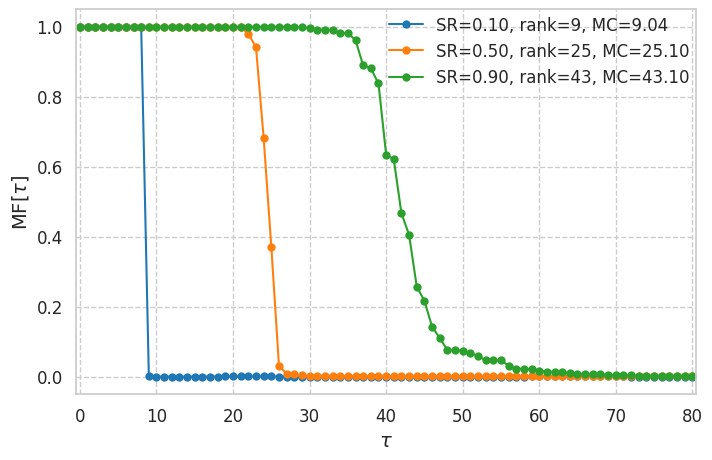

In [8]:
seed = 1234
dim = 50
t_washout = 1000
t_sample = 20000
t_total = t_washout + t_sample
display = True

rnd = np.random.default_rng(seed)
srs = np.array([0.1, 0.5, 0.9])
w_in = Linear(1, dim, bound=0.1, bias=0.0, rnd=rnd)

# net = ESN(dim, sr=srs[:, None], f=np.tanh, p=1, rnd=rnd)
net = ESN(dim, sr=srs[:, None], f=lambda t: t, p=1, rnd=rnd)  # Linear reservoir.
# net.weight[:] = np.roll(np.eye(dim), 1, axis=0)  # Ring topology.

x0 = np.zeros((srs.shape[0], dim))
us = rnd.uniform(-1, 1, (t_total, 1))

x = x0
xs = np.zeros((t_total, *x0.shape))
for idx in trange(t_total, display=display):
    x = net(x, w_in(us[idx]))
    xs[idx] = x

taus = np.arange(0, 81)
r2s = None
U, mask, ranks = calc_regression_and_rank(xs[t_washout:].swapaxes(0, -2))
for idx, tau in enumerate(tqdm(taus, display=display)):
    zeta = us[t_washout - tau : t_total - tau]
    r2 = calc_memory_function(U, mask, zeta)[..., 0]
    if r2s is None:
        r2s = np.zeros((taus.shape[0], *r2.shape))
    r2s[idx] = r2
mcs = np.sum(r2s, axis=0)
labels = []
for sr, rank, mc in zip(srs, ranks, mcs, strict=True):
    labels.append(f"SR={sr:.2f}, rank={rank}, MC={mc:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.plot(taus, r2s, "o-", label=labels)
ax.set_xlim(taus.min() - 0.5, taus.max() + 0.5)
ax.set_ylim(-0.05, 1.05)
ax.legend(
    loc="upper right",
    borderaxespad=0,
    ncol=1,
    fontsize=12,
    frameon=False,
)
ax.set_xlabel(r"$\tau$", fontsize=14)
ax.set_ylabel(r"$\mathrm{MF}[\tau]$", fontsize=14)
ax.tick_params(axis="both", which="major", labelsize=12)

None

Let's set the spectral radius of the ESN in more detail this time and examine its relationship with memory capacity.
The following cell calculates the memory capacity of the ESN and displays both the rank and the memory capacity simultaneously (by default, the spectral radius is set from 0.0 to 1.5 in increments of 0.05).
Confirm that the memory capacity is always less than the rank and that the memory capacity increases as the spectral radius approaches 1.

  0%|          | 0/21000 [00:00<?, ?it/s]

  0%|          | 0/81 [00:00<?, ?it/s]

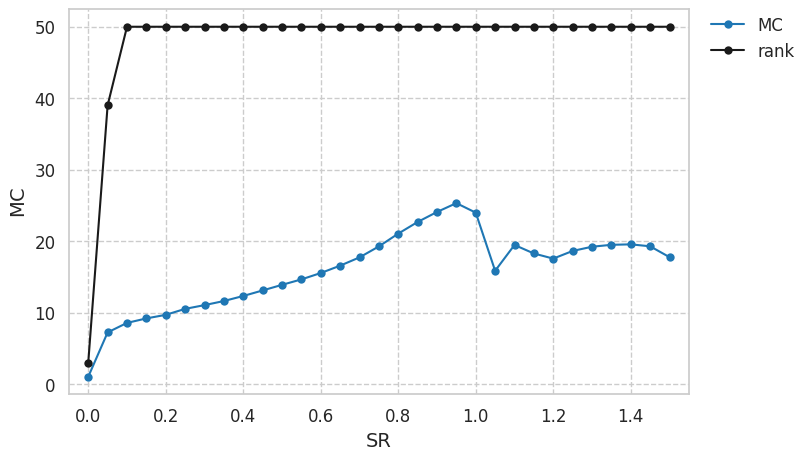

In [13]:
seed = 1234
dim = 50
t_washout = 1000
t_sample = 20000
t_total = t_washout + t_sample
display = True

rnd = np.random.default_rng(seed)
srs = np.linspace(0.0, 1.5, 31)
w_in = Linear(1, dim, bound=0.1, bias=0.0, rnd=rnd)

net = ESN(dim, sr=srs[:, None], f=np.tanh, p=1, rnd=rnd)
# net = ESN(dim, sr=srs[:, None], f=lambda t: t, p=1, rnd=rnd)

x0 = np.zeros((srs.shape[0], dim))
us = rnd.uniform(-1, 1, (t_total, 1))

x = x0
xs = np.zeros((t_total, *x0.shape))
for idx in trange(t_total, display=display):
    x = net(x, w_in(us[idx]))
    xs[idx] = x

taus = np.arange(0, 81)
r2s = None
U, mask, ranks = calc_regression_and_rank(xs[t_washout:].swapaxes(0, -2))
for idx, tau in enumerate(tqdm(taus, display=display)):
    zeta = us[t_washout - tau : t_total - tau]
    r2 = calc_memory_function(U, mask, zeta)[..., 0]
    if r2s is None:
        r2s = np.zeros((taus.shape[0], *r2.shape))
    r2s[idx] = r2
mcs = np.sum(r2s, axis=0)

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.plot(srs, mcs, "o-", label="MC")
ax.plot(srs, ranks, "o-", color="k", label="rank")
ax.set_xlim(srs.min() - 0.05, srs.max() + 0.05)
# ax.set_ylim(-0.1, dim + 0.1)
ax.legend(
    loc="upper left",
    borderaxespad=0,
    bbox_to_anchor=(1.025, 1.0),
    ncol=1,
    fontsize=12,
    frameon=False,
)
ax.set_xlabel(r"SR", fontsize=14)
ax.set_ylabel(r"$\mathrm{MC}$", fontsize=14)
ax.tick_params(axis="both", which="major", labelsize=12)

None

  0%|          | 0/21000 [00:00<?, ?it/s]

  0%|          | 0/81 [00:00<?, ?it/s]

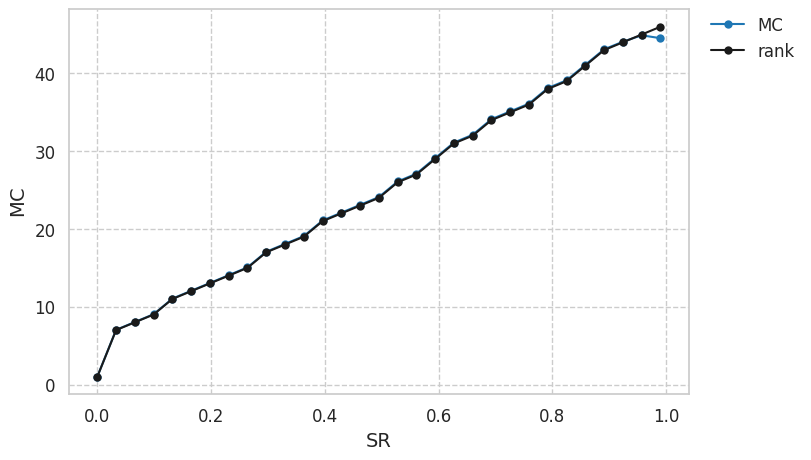

In [16]:
seed = 1234
dim = 50
t_washout = 1000
t_sample = 20000
t_total = t_washout + t_sample
display = True

rnd = np.random.default_rng(seed)
srs = np.linspace(0.0, 0.99, 31)
w_in = Linear(1, dim, bound=0.1, bias=0.0, rnd=rnd)

# net = ESN(dim, sr=srs[:, None], f=np.tanh, p=1, rnd=rnd)
net = ESN(dim, sr=srs[:, None], f=lambda t: t, p=1, rnd=rnd)

x0 = np.zeros((srs.shape[0], dim))
us = rnd.uniform(-1, 1, (t_total, 1))

x = x0
xs = np.zeros((t_total, *x0.shape))
for idx in trange(t_total, display=display):
    x = net(x, w_in(us[idx]))
    xs[idx] = x

taus = np.arange(0, 81)
r2s = None
U, mask, ranks = calc_regression_and_rank(xs[t_washout:].swapaxes(0, -2))
for idx, tau in enumerate(tqdm(taus, display=display)):
    zeta = us[t_washout - tau : t_total - tau]
    r2 = calc_memory_function(U, mask, zeta)[..., 0]
    if r2s is None:
        r2s = np.zeros((taus.shape[0], *r2.shape))
    r2s[idx] = r2
mcs = np.sum(r2s, axis=0)

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.plot(srs, mcs, "o-", label="MC")
ax.plot(srs, ranks, "o-", color="k", label="rank")
ax.set_xlim(srs.min() - 0.05, srs.max() + 0.05)
# ax.set_ylim(-0.1, dim + 0.1)
ax.legend(
    loc="upper left",
    borderaxespad=0,
    bbox_to_anchor=(1.025, 1.0),
    ncol=1,
    fontsize=12,
    frameon=False,
)
ax.set_xlabel(r"SR", fontsize=14)
ax.set_ylabel(r"$\mathrm{MC}$", fontsize=14)
ax.tick_params(axis="both", which="major", labelsize=12)

None

Let's examine the relationship with the maximum Lyapunov exponent that we learned in the previous chapter.
The following cell calculates the maximum Lyapunov exponent of the ESN simultaneously and visualizes its relationship with memory capacity.
Note that it may take some time to execute since the spectral radius is set at 200 points in increments of 0.01 up to 2.0.

  0%|          | 0/11000 [00:00<?, ?it/s]

  0%|          | 0/81 [00:00<?, ?it/s]

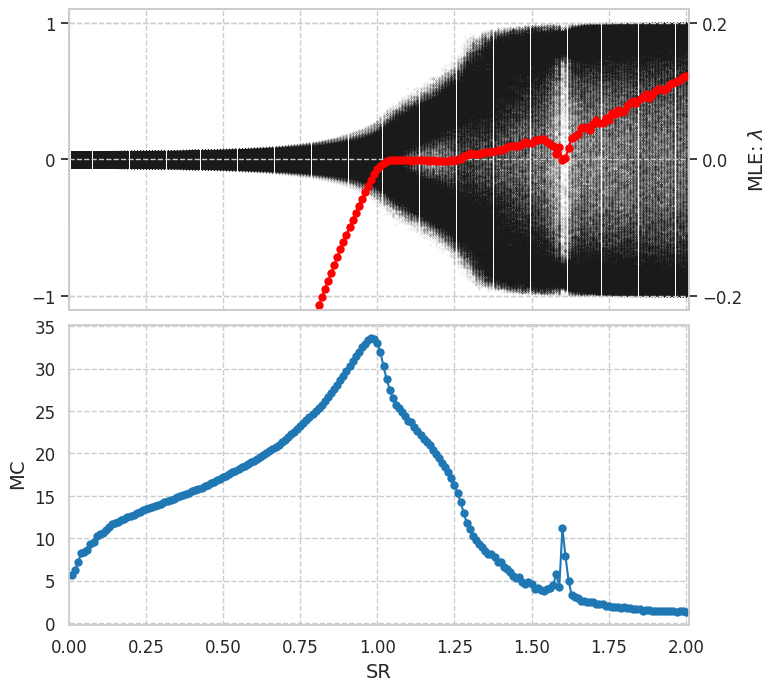

In [17]:
seed = 12345
dim = 100
eps = 1e-4
t_washout = 1000
t_sample = 10000
t_total = t_washout + t_sample
ts = np.arange(-t_washout, t_sample)
display = True

rnd = np.random.default_rng(seed)
srs = np.linspace(0.01, 2.0, 200)
w_in = Linear(1, dim, bound=0.1, bias=0.0, rnd=rnd)

net = ESN(dim, sr=srs[:, None], f=np.tanh, p=1, rnd=rnd)
# net = ESN(dim, sr=srs[:, None], f=lambda t: t, p=1, rnd=rnd)

x0 = np.zeros((2, srs.shape[0], dim))
us = rnd.uniform(-1, 1, (t_total, 1))

x = x0
xs = np.zeros((t_total, *x0.shape[1:]))
lmbds = np.zeros((t_sample, srs.shape[0]))
for idx, t in enumerate(tqdm(ts, display=display)):
    if t == 0:
        pert = rnd.uniform(-1, 1, x[0].shape)
        pert = pert / np.linalg.norm(pert, axis=-1, keepdims=True)
        x[1] = x[0] + pert * eps
    x = net(x, w_in(us[idx]))
    xs[idx] = x[0]
    if t >= 0:
        x_org, x_per = x[0], x[1]
        x_diff = x_per - x_org
        d_post = np.linalg.norm(x_diff, axis=-1, keepdims=True)
        lmbd = np.log(np.abs(d_post / eps))
        x_per[:] = x_org + x_diff * (eps / d_post)
        lmbds[idx - t_washout] = lmbd[..., 0]

taus = np.arange(0, 81)
r2s = None
U, mask, ranks = calc_regression_and_rank(xs[t_washout:].swapaxes(0, -2))
for idx, tau in enumerate(tqdm(taus, display=display)):
    zeta = us[t_washout - tau : t_total - tau]
    r2 = calc_memory_function(U, mask, zeta)[..., 0]
    if r2s is None:
        r2s = np.zeros((taus.shape[0], *r2.shape))
    r2s[idx] = r2
mcs = np.sum(r2s, axis=0)


def get_maxima_and_minima(xs, **kwargs):
    id_maxima = sp.signal.find_peaks(xs, **kwargs)[0]
    id_minima = sp.signal.find_peaks(-xs, **kwargs)[0]
    return id_maxima, id_minima


fig, ax = plt.subplots(2, 1, figsize=(8, 8), gridspec_kw={"hspace": 0.05})
axl = ax[0]
axl.set_xlim(srs.min() - 0.01, srs.max() + 0.01)
axl.set_xticklabels([])
for idx, sr in enumerate(srs):
    id_maxima, id_minima = get_maxima_and_minima(xs[t_washout:, idx, 0])
    id_all = np.concatenate([id_maxima, id_minima])
    peaks = xs[t_washout:, idx, 0][id_all]
    axl.scatter(sr * np.ones(peaks.shape[0]), peaks, marker=".", s=0.01, color="k")
axl.tick_params(axis="both", which="major", labelsize=12)
axl.set_xlabel(r"$x_0[k]$", fontsize=14)
axl.set_yticks([-1.0, 0.0, 1.0])
axl.set_ylim(-1.1, 1.1)

axr = ax[0].twinx()
axr.plot(srs, lmbds.mean(axis=0), "o-", color="red", label="MLE")
axr.set_yticks([-0.2, 0.0, 0.2])
axr.set_ylim(-0.22, 0.22)
axr.set_ylabel(r"MLE: $\lambda$", fontsize=14)
axr.set_xticklabels([])
axr.tick_params(axis="both", which="major", labelsize=12)

ax[1].plot(srs, mcs, "o-", label="MC")
ax[1].set_xlim(srs.min() - 0.01, srs.max() + 0.01)
ax[1].set_xlabel(r"SR", fontsize=14)
ax[1].set_ylabel(r"$\mathrm{MC}$", fontsize=14)
ax[1].tick_params(axis="both", which="major", labelsize=12)

None

  0%|          | 0/11000 [00:00<?, ?it/s]

  0%|          | 0/81 [00:00<?, ?it/s]

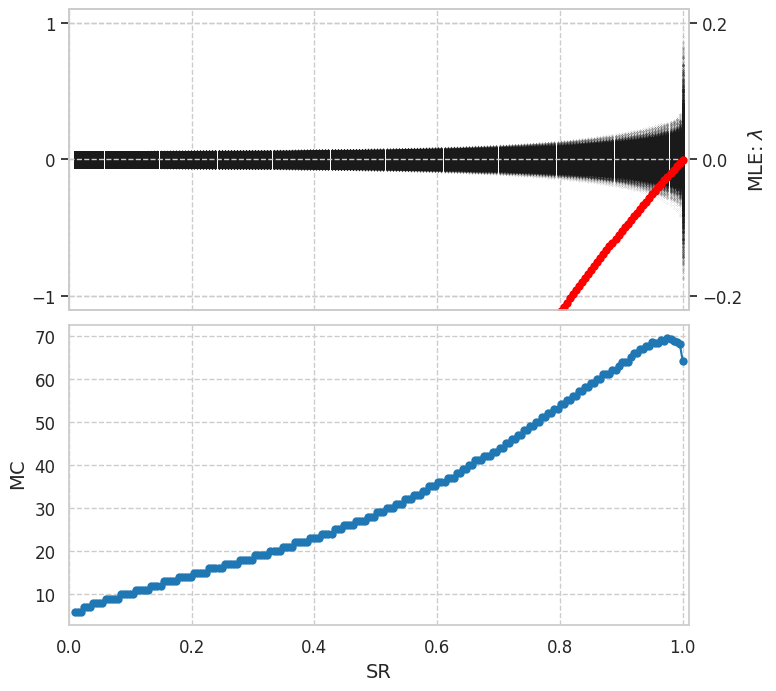

In [18]:
seed = 12345
dim = 100
eps = 1e-4
t_washout = 1000
t_sample = 10000
t_total = t_washout + t_sample
ts = np.arange(-t_washout, t_sample)
display = True

rnd = np.random.default_rng(seed)
srs = np.linspace(0.01, 1.0, 200)
w_in = Linear(1, dim, bound=0.1, bias=0.0, rnd=rnd)

# net = ESN(dim, sr=srs[:, None], f=np.tanh, p=1, rnd=rnd)
net = ESN(dim, sr=srs[:, None], f=lambda t: t, p=1, rnd=rnd)

x0 = np.zeros((2, srs.shape[0], dim))
us = rnd.uniform(-1, 1, (t_total, 1))

x = x0
xs = np.zeros((t_total, *x0.shape[1:]))
lmbds = np.zeros((t_sample, srs.shape[0]))
for idx, t in enumerate(tqdm(ts, display=display)):
    if t == 0:
        pert = rnd.uniform(-1, 1, x[0].shape)
        pert = pert / np.linalg.norm(pert, axis=-1, keepdims=True)
        x[1] = x[0] + pert * eps
    x = net(x, w_in(us[idx]))
    xs[idx] = x[0]
    if t >= 0:
        x_org, x_per = x[0], x[1]
        x_diff = x_per - x_org
        d_post = np.linalg.norm(x_diff, axis=-1, keepdims=True)
        lmbd = np.log(np.abs(d_post / eps))
        x_per[:] = x_org + x_diff * (eps / d_post)
        lmbds[idx - t_washout] = lmbd[..., 0]

taus = np.arange(0, 81)
r2s = None
U, mask, ranks = calc_regression_and_rank(xs[t_washout:].swapaxes(0, -2))
for idx, tau in enumerate(tqdm(taus, display=display)):
    zeta = us[t_washout - tau : t_total - tau]
    r2 = calc_memory_function(U, mask, zeta)[..., 0]
    if r2s is None:
        r2s = np.zeros((taus.shape[0], *r2.shape))
    r2s[idx] = r2
mcs = np.sum(r2s, axis=0)


def get_maxima_and_minima(xs, **kwargs):
    id_maxima = sp.signal.find_peaks(xs, **kwargs)[0]
    id_minima = sp.signal.find_peaks(-xs, **kwargs)[0]
    return id_maxima, id_minima


fig, ax = plt.subplots(2, 1, figsize=(8, 8), gridspec_kw={"hspace": 0.05})
axl = ax[0]
axl.set_xlim(srs.min() - 0.01, srs.max() + 0.01)
axl.set_xticklabels([])
for idx, sr in enumerate(srs):
    id_maxima, id_minima = get_maxima_and_minima(xs[t_washout:, idx, 0])
    id_all = np.concatenate([id_maxima, id_minima])
    peaks = xs[t_washout:, idx, 0][id_all]
    axl.scatter(sr * np.ones(peaks.shape[0]), peaks, marker=".", s=0.01, color="k")
axl.tick_params(axis="both", which="major", labelsize=12)
axl.set_xlabel(r"$x_0[k]$", fontsize=14)
axl.set_yticks([-1.0, 0.0, 1.0])
axl.set_ylim(-1.1, 1.1)

axr = ax[0].twinx()
axr.plot(srs, lmbds.mean(axis=0), "o-", color="red", label="MLE")
axr.set_yticks([-0.2, 0.0, 0.2])
axr.set_ylim(-0.22, 0.22)
axr.set_ylabel(r"MLE: $\lambda$", fontsize=14)
axr.set_xticklabels([])
axr.tick_params(axis="both", which="major", labelsize=12)

ax[1].plot(srs, mcs, "o-", label="MC")
ax[1].set_xlim(srs.min() - 0.01, srs.max() + 0.01)
ax[1].set_xlabel(r"SR", fontsize=14)
ax[1].set_ylabel(r"$\mathrm{MC}$", fontsize=14)
ax[1].tick_params(axis="both", which="major", labelsize=12)

None

Q2.1. (Advanced)

- Observe how the behavior changes by varying the parameters. In particular, investigate the relationship between the activation function and memory function/capacity.
- In the demonstration above, the input distribution uses uniform random noise, but other distributions (e.g., normal distribution or Bernoulli distribution) can also be used. Observe how memory function/capacity changes when the input distribution is altered.
- Investigate relationship between capacity and activation function.

## Reference

[1] Jaeger, H. (2001). *Short term memory in echo state networks*. GMD Forschungszentrum Informationstechnik. https://doi.org/10.24406/publica-fhg-291107